# Source Code

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as la

## Marchenko-Pastur Law

In [23]:
def generate_random_normal(p, n):
    return np.random.normal(0, 1, size=(p, n))

def compute_singular_values(matrix): 
    p, n = matrix.shape
    covariance_matrix = np.matmul(matrix, np.transpose(matrix)) / n

    return la.eigvalsh(covariance_matrix)

def compute_marchenko_pastur(gamma, step=1000):
    a_plus = (1 + math.sqrt(gamma)) ** 2
    a_minus = (1 - math.sqrt(gamma)) ** 2
    
    x_values = np.linspace(a_minus, a_plus, step)
    y_values = np.sqrt((a_plus - x_values) * (x_values - a_minus)) / (2 * np.pi * gamma * x_values)

    point_mass = 1.0 - (1.0 / gamma) if gamma > 1 else None

    return point_mass, x_values, y_values
        
# The helper function below creates tthe histogram of the singular values of a matrix and 
# the marchenko pastur distribution on the same plot.

def generate_plot(matrix):
    singular_values = compute_singular_values(matrix)
    plt.hist(singular_values, bins=30, color='skyblue', edgecolor='black', density=True)

    p, n = matrix.shape
    gamma = p / n
    
    point_mass, x_values, y_values = compute_marchenko_pastur(gamma)
    plt.plot(x_values, y_values, color='red')

    if point_mass:
        plt.vlines(0, 0, point_mass, color="red")
        plt.plot(0, point_mass, "ro", markersize=8)

    plt.show()

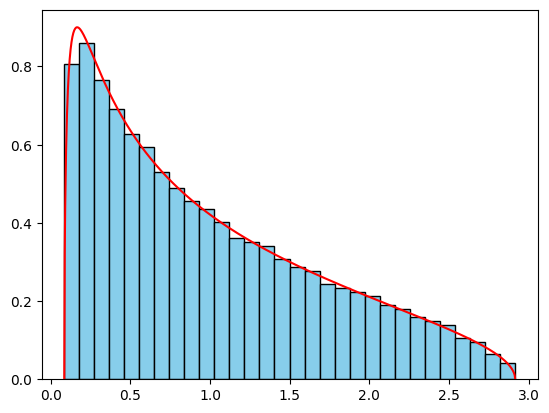

In [32]:
matrix = generate_random_normal(1000, 2000)
generate_plot(matrix)

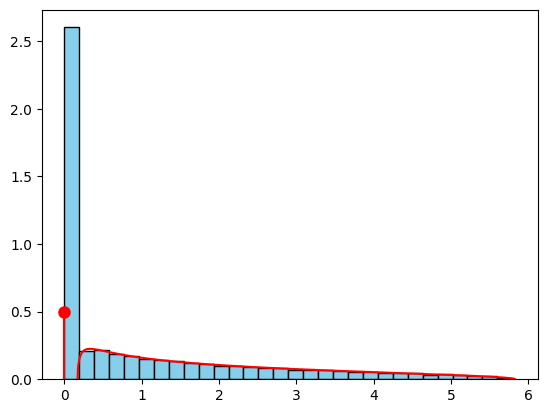

In [33]:
matrix = generate_random_normal(2000, 1000)
generate_plot(matrix)

## Neural Network

In [ ]:
# ...more coming soon...